In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [9]:
rng = np.random.default_rng(42)

ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)

ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, -1), "down": (0, 1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
        
    return next_state, -0.04, False

In [3]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))

alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    return int(np.argmax(Q[state]))

training_returns = []

for episode in range(5000):
    state, episode_return = START, 0.0
    
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        
        if done:
            break
            
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

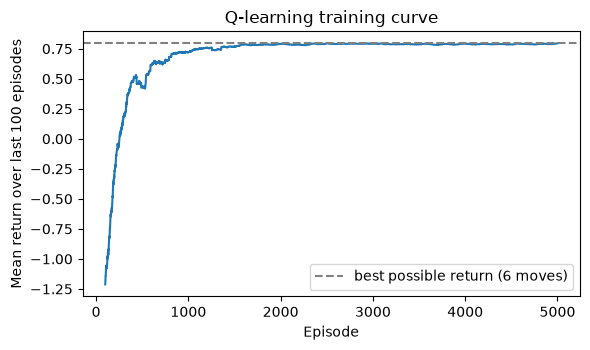

In [5]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
successes, returns = 0, []

for _ in range(200):
    state, total = START, 0.0
    
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        
        if done:
            successes += int(state == GOAL)
            break
            
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


In [7]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)

Q_loaded = np.load(q_path)
policy = np.full((ROWS, COLS), "", dtype=object)

for r in range(ROWS):
    for c in range(COLS):
        if (r, c) == GOAL:
            policy[r, c] = "GOAL"
        elif (r, c) == TRAP:
            policy[r, c] = "TRAP"
        else:
            policy[r, c] = ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]

print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['down' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


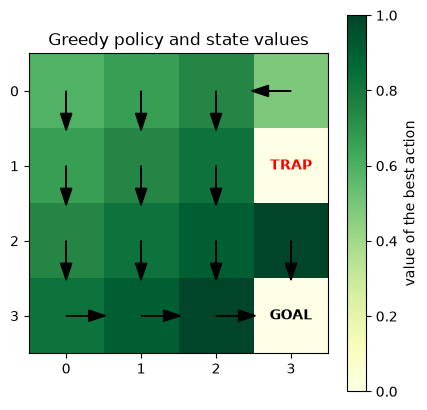

In [11]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, 0.3 * dy, head_width=0.15, color="black")
                
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values")